In [ ]:
from pathlib import Path
from collections import Counter

import cv2
import numpy as np
import matplotlib.pyplot as plt

print("imported")

imported


In [2]:
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "data"
 
print("Dataset exists:", DATA_DIR.exists())

Dataset exists: True


In [3]:
for path in sorted(DATA_DIR.iterdir()):
    print(f"Dir {path.name}")

Dir glioma
Dir meningioma
Dir notumor
Dir pituitary


In [4]:
subdirectories = sorted(
    path for path in DATA_DIR.iterdir()
    if path.is_dir()
)

print(f"Number of immediate subdirectories: {len(subdirectories)}")

for directory in subdirectories:
    child_directories = [
        path.name for path in directory.iterdir()
        if path.is_dir()
    ]

    print(f"\n{directory.name}/")

    if child_directories:
        for child in sorted(child_directories):
            print(f"    {child}/")
    else:
        print("    No nested directories")

Number of immediate subdirectories: 4

glioma/
    No nested directories

meningioma/
    No nested directories

notumor/
    No nested directories

pituitary/
    No nested directories


In [5]:
SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

class_dirs = sorted(
    path for path in DATA_DIR.iterdir() if path.is_dir()
)
if not class_dirs:
    raise ValueError("No class folders found, check the dataset path")

class_images = {}
extention_counts = Counter()
for class_dir in class_dirs:
    images = sorted(
        path for path in class_dir.rglob("*")
        if path.is_file() 
        and path.suffix.lower() in SUPPORTED_EXTENSIONS
    )

    class_images[class_dir.name] = images
    for image_path in images:
        extention_counts[image_path.suffix.lower()] += 1
print("Class distribution")
print("-" * 55)
for class_name, images in class_images.items():
    print(f"{class_name} {len(images)}")

print("Supported image extensions", extention_counts)
print(
    "\n total supported images:", sum(len(images) for images in class_images.values())
)

Class distribution
-------------------------------------------------------
glioma 1621
meningioma 1645
notumor 2000
pituitary 1757
Supported image extensions Counter({'.jpg': 7023})

 total supported images: 7023


In [6]:
all_files = [
    path for path in DATA_DIR.rglob("*")
    if path.is_file()
]
unsupported_files = [
    path for path in all_files
    if path.suffix.lower() not in SUPPORTED_EXTENSIONS
]
unreadable_images = []
for images in class_images.values():
    for image_path in images:
        image = cv2.imread(str(image_path))

        if image is None:
            unreadable_images.append(image_path)
print("Unsupported files:", len(unsupported_files))
print("Unreadable images:", len(unreadable_images))

Unsupported files: 0
Unreadable images: 0


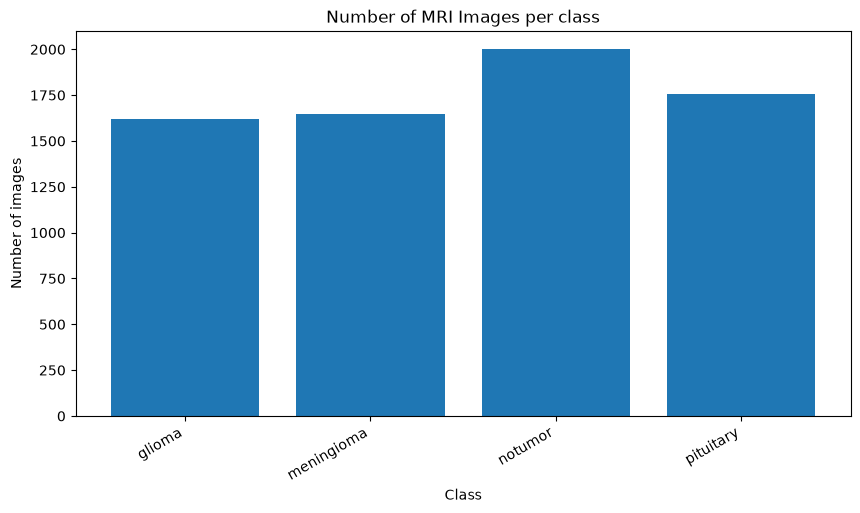

In [7]:
class_names = list(class_images.keys())
class_counts = [
    len(class_images[name])
    for name in class_names
]
plt.figure(figsize=(10, 5))
plt.bar(class_names, class_counts)
plt.title("Number of MRI Images per class")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.xticks(rotation=30, ha="right")
plt.show()

In [8]:
type(unreadable_images)
bad_paths = {bad_path for _, bad_path in unreadable_images
        }

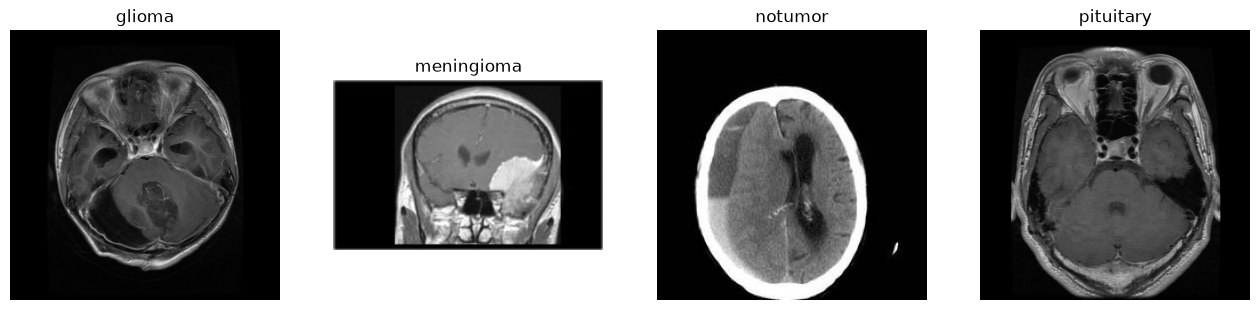

In [9]:
non_empty_classes = [
    name for name in class_names
    if any(
        path not in bad_paths
        for path in class_images[name] 
        
    )
]

fig, axes = plt.subplots(
    1, len(non_empty_classes),
    figsize=(4 * len(non_empty_classes), 4),
    squeeze=False,
)

unreadable_paths = {
    path for _, path in unreadable_images
}
for ax, class_name in zip(axes[0], non_empty_classes):
    candidates = [
        path for path in class_images[class_name]
        if path not in unreadable_paths
    ]
    path = candidates[0]
    image = cv2.imread(str(path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    ax.imshow(image)
    ax.set_title(class_name)
    ax.axis("off")
plt.show()

In [10]:
image_shapes = []
shape_errors = []

for class_name in class_names:
    for path in class_images[class_name]:
        if path in unreadable_paths:
            continue

        image = cv2.imread(str(path))

        if image is None:
            shape_errors.append(path)
            continue

        height, width, channels = image.shape
        image_shapes.append((height, width, channels))

print("Readable images inspected:", len(image_shapes))
print("Images that could not be read:", len(shape_errors))

if image_shapes:
    shapes = np.array(image_shapes)

    print("Minimum dimensions (H, W, C):", shapes.min(axis=0))
    print("Maximum dimensions (H, W, C):", shapes.max(axis=0))
    print("Most common shapes:")
    print(Counter(image_shapes).most_common(10))

Readable images inspected: 7023
Images that could not be read: 0
Minimum dimensions (H, W, C): [168 150   3]
Maximum dimensions (H, W, C): [1446 1920    3]
Most common shapes:
[((512, 512, 3), 4742), ((225, 225, 3), 332), ((630, 630, 3), 90), ((236, 236, 3), 81), ((251, 201, 3), 58), ((221, 228, 3), 51), ((217, 232, 3), 50), ((168, 300, 3), 49), ((442, 442, 3), 46), ((198, 150, 3), 44)]


In [14]:
IMG_SIZE = (224, 224)
resized_images = {}
resize_errors = []
for class_name in class_names:
    resized_images[class_name] = []
    for path in class_images[class_name]:
        if path in unreadable_paths:
            continue
        image = cv2.imread(str(path))
        if image is None:
            resize_errors.append(path)
        resized = cv2.resize(
            image, 
            IMG_SIZE,
            interpolation=cv2.INTER_AREA
        )
        resized_images[class_name].append(resized)
print("resizing completed!")
for class_name in class_names:
    print(
        f"{class_name}: "
        f"{len(resized_images[class_name])} resized images"
    )

print("Resize errors:", len(resize_errors))

resizing completed!
glioma: 1621 resized images
meningioma: 1645 resized images
notumor: 2000 resized images
pituitary: 1757 resized images
Resize errors: 0


In [15]:
for class_name in class_names:
    if resized_images[class_name]:
        image = resized_images[class_name][0]

        print(
            f"{class_name}: "
            f"shape={image.shape}, "
            f"dtype={image.dtype}"
        )

glioma: shape=(224, 224, 3), dtype=uint8
meningioma: shape=(224, 224, 3), dtype=uint8
notumor: shape=(224, 224, 3), dtype=uint8
pituitary: shape=(224, 224, 3), dtype=uint8


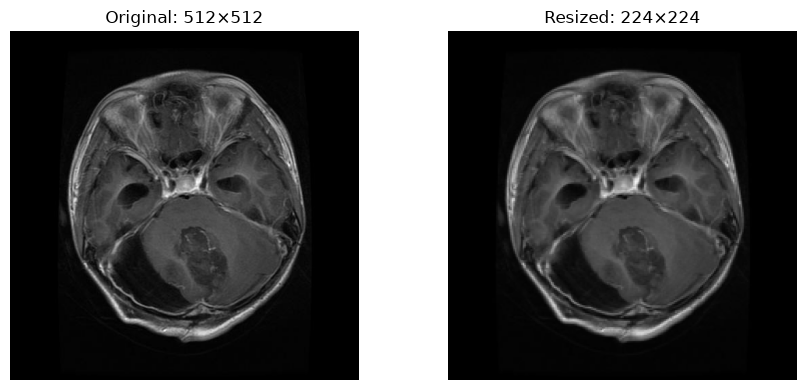

In [16]:
class_name = next(
    name for name in class_names
    if resized_images[name]
)

original_path = next(
    path for path in class_images[class_name]
    if path not in unreadable_paths
)

original = cv2.imread(str(original_path))
original_rgb = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

resized = resized_images[class_name][0]
resized_rgb = cv2.cvtColor(resized, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(original_rgb)
axes[0].set_title(f"Original: {original.shape[1]}×{original.shape[0]}")
axes[0].axis("off")

axes[1].imshow(resized_rgb)
axes[1].set_title("Resized: 224×224")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [19]:
images = []
labels = []
for class_name in class_names:
    for image in resized_images[class_name]:
        images.append(image)
        labels.append(class_name)
print("Total images: ", len(images))
print("Total labels: ", len(labels))

Total images:  7023
Total labels:  7023


In [24]:
X = np.array(images)
y = np.array(labels)

print("X shape: ", X.shape)
print("y shape: ", y.shape)
print(X.ndim)
print(y.ndim)

X shape:  (7023, 224, 224, 3)
y shape:  (7023,)
4
1


In [22]:
assert len(X) == len(y), "Images and labels have different lengths!"
assert X.ndim == 4, "Expected images with shape (N, H, W, C)"
assert X.shape[1:3] == (224, 224), "Unexpected image dimensions"

print("Unique classes:", np.unique(y))
print("Images and labels are aligned.")

Unique classes: ['glioma' 'meningioma' 'notumor' 'pituitary']
Images and labels are aligned.


In [ ]:
import pandas as pd 
classes, counts = np.unique(y, return_counts=True)

class_balance = pd.DataFrame({
    "class": classes,
    "image_count": counts,
    "percentage": counts / len(y) * 100,
})
class_balance["percentage"] = class_balance["percentage"].round(2)
print(class_balance.to_string(index=False))

     class  image_count  percentage
    glioma         1621       23.08
meningioma         1645       23.42
   notumor         2000       28.48
 pituitary         1757       25.02


In [28]:
max_count = counts.max()
min_count = counts.min()

imbalance_ration = max_count  / min_count
print(f"Majority class: {classes[counts.argmax()]}")
print(f"Minority class: {classes[counts.argmin()]}")
print(f"Imbalance ratio: {imbalance_ration}")

Majority class: notumor
Minority class: glioma
Imbalance ratio: 1.2338062924120914


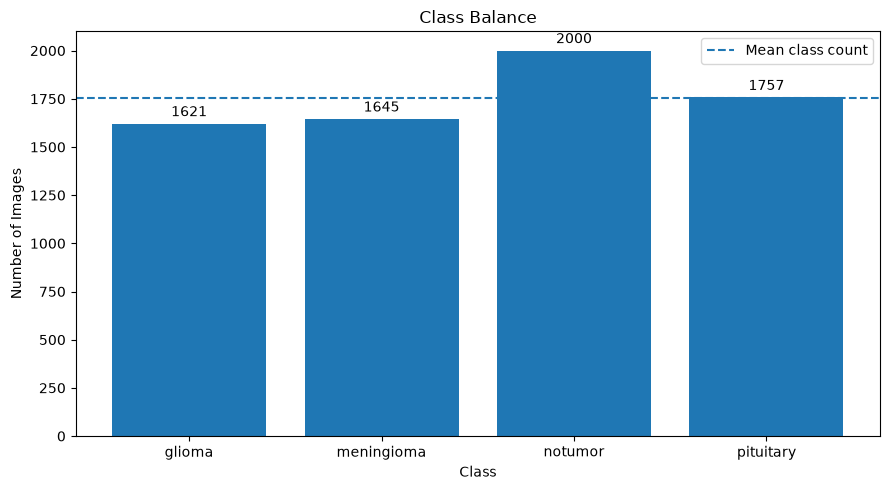

In [35]:

plt.figure(figsize=(9, 5))

bars = plt.bar(classes, counts)

plt.bar_label(bars, padding=3)
plt.axhline(
    counts.mean(),
    linestyle="--",
    label="Mean class count",
)

plt.title("Class Balance")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.legend()
plt.tight_layout()
plt.show()

In [38]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

y_encoded = le.fit_transform(y)
print("Original labels: ", y[:10])
print("Encoded labels: ", y_encoded[:10])
print("Class names: ", le.classes_)

Original labels:  ['glioma' 'glioma' 'glioma' 'glioma' 'glioma' 'glioma' 'glioma' 'glioma'
 'glioma' 'glioma']
Encoded labels:  [0 0 0 0 0 0 0 0 0 0]
Class names:  ['glioma' 'meningioma' 'notumor' 'pituitary']


In [41]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("training images: ", X_train.shape)
print("training labels: ", y_train.shape)
print()
print("test images: ", X_test.shape)
print("test labels: ", y_test.shape)

training images:  (5618, 224, 224, 3)
training labels:  (5618,)

test images:  (1405, 224, 224, 3)
test labels:  (1405,)


In [42]:
import pandas as pd
import numpy as np

class_names_encoded = le.classes_

train_counts = np.bincount(
    y_train,
    minlength=len(class_names_encoded),
)

test_counts = np.bincount(
    y_test,
    minlength=len(class_names_encoded),
)

split_summary = pd.DataFrame({
    "class": class_names_encoded,
    "train_count": train_counts,
    "test_count": test_counts,
})

print(split_summary.to_string(index=False))

     class  train_count  test_count
    glioma         1297         324
meningioma         1316         329
   notumor         1600         400
 pituitary         1405         352


In [ ]:
X_train = X_train.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

print("X_train:")
print("  Shape:", X_train.shape)
print("  Dtype:", X_train.dtype)
print("  Min pixel value:", X_train.min())
print("  Max pixel value:", X_train.max())

print("\nX_test:")
print("  Shape:", X_test.shape)
print("  Dtype:", X_test.dtype)
print("  Min pixel value:", X_test.min())
print("  Max pixel value:", X_test.max())

X_train:
  Shape: (5618, 224, 224, 3)
  Dtype: float32
  Min pixel value: 0.0
  Max pixel value: 1.0

X_test:
  Shape: (1405, 224, 224, 3)
  Dtype: float32
  Min pixel value: 0.0
  Max pixel value: 1.0


: 